In [3]:
pip install yfinance pandas numpy

^C
Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import numpy as np
import pandas as pd
import yfinance as yf

# settings
START_DATE = "2018-01-01"
END_DATE = "2026-01-01"

symbols = {
    "Gold": "GC=F",   # gold futures
    "Bitcoin": "BTC-USD"
}

raw_dir = "data/raw"
processed_dir = "data/processed"

os.makedirs(raw_dir, exist_ok=True)
os.makedirs(processed_dir, exist_ok=True)

# download adjusted close prices
prices = {}

for asset_name, ticker in symbols.items():
    df = yf.download(ticker, start=START_DATE, end=END_DATE, auto_adjust=True)

    if df.empty:
        raise ValueError(f"No data donwloaded for {asset_name}: {ticker}")
    
    prices[asset_name] = df["Close"]

prices_df = pd.concat(prices, axis=1)
prices_df.columns = ["Gold", "Bitcoin"]

# clean price data
prices_df = prices_df.dropna()

# compute log returns
returns_df = 100 * np.log(prices_df / prices_df.shift(1))
returns_df = returns_df.dropna()

# save files
prices_df.to_csv(f"{raw_dir}/gold_bitcoin_prices.csv")
returns_df.to_csv(f"{processed_dir}/gold_bitcoin_log_returns.csv")

# basic checks
print("Prices shape:", prices_df.shape)
print("Returns shape:", returns_df.shape)

print("\nPrice data:")
display(prices_df.head())

print("\nReturn data:")
display(returns_df.head())

print("\nMissing values in prices")
print(prices_df.isna().sum())

print("\nMissing values in returns:")
print(returns_df.isna().sum())

print("\nReturn summary:")
display(returns_df.describe())

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Prices shape: (2012, 2)
Returns shape: (2011, 2)

Price data:


,Gold,Bitcoin
Date,,
2018-01-02,1313.699951,14982.099609
2018-01-03,1316.199951,15201.000000
2018-01-04,1319.400024,15599.200195
2018-01-05,1320.300049,17429.500000
2018-01-08,1318.599976,15170.099609



Return data:


,Gold,Bitcoin
Date,,
2018-01-03,0.190121,1.450509
2018-01-04,0.242835,2.585843
2018-01-05,0.068191,11.094453
2018-01-08,-0.128847,-13.883781
2018-01-09,-0.524658,-3.861992



Missing values in prices
Gold       0
Bitcoin    0
dtype: int64

Missing values in returns:
Gold       0
Bitcoin    0
dtype: int64

Return summary:


,Gold,Bitcoin
count,2011.000000,2011.000000
mean,0.059259,0.087761
std,0.994704,4.120451
min,-5.906204,-46.473018
25%,-0.412817,-1.657412
50%,0.077515,0.096761
75%,0.595834,1.985474
max,5.777508,20.304640


Bitcoin observations were aligned to Gold trading days to facilitate direct comparison of statistical properties and risk measures.

In [ ]:
pip install statsmodels arch scipy

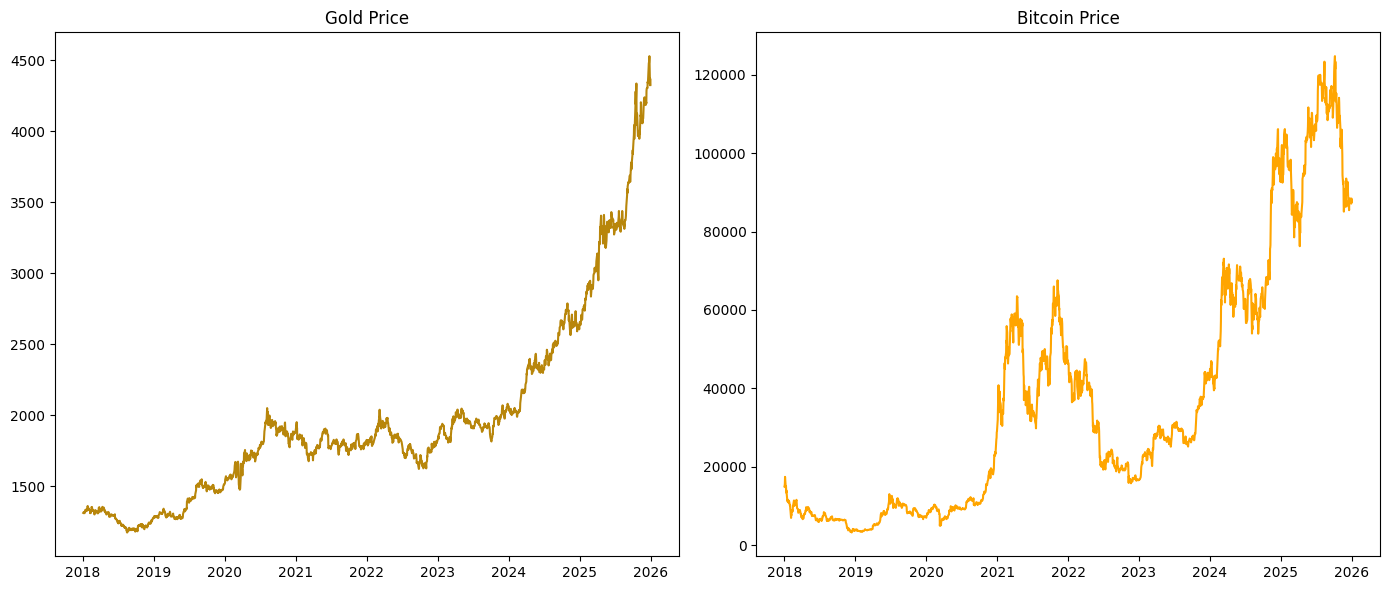

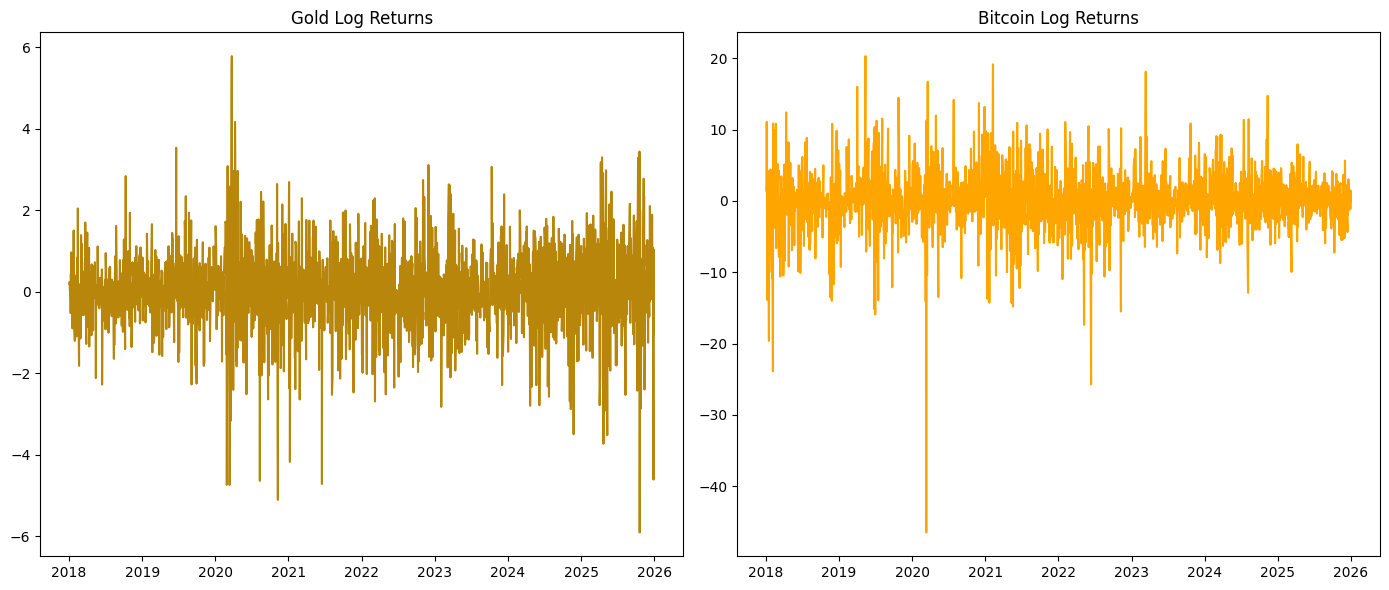


ADF TEST: Gold Price
Statistic : 4.4216
P-value : 1.000000

KPSS TEST: Gold Price
Statistic: 5.0927
P-value: 0.010000

ADF TEST: Bitcoin Price
Statistic : -1.1156
P-value : 0.708825

KPSS TEST: Bitcoin Price
Statistic: 4.9112
P-value: 0.010000

ADF TEST: Gold Returns
Statistic : -19.0589
P-value : 0.000000

KPSS TEST: Gold Returns
Statistic: 0.4510
P-value: 0.055156


C:\Users\user\AppData\Local\Temp\ipykernel_20136\425073917.py:44: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat, pval, lags, crit = kpss(
C:\Users\user\AppData\Local\Temp\ipykernel_20136\425073917.py:44: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat, pval, lags, crit = kpss(



ADF TEST: Bitcoin Returns
Statistic : -24.3238
P-value : 0.000000

KPSS TEST: Bitcoin Returns
Statistic: 0.1459
P-value: 0.100000


C:\Users\user\AppData\Local\Temp\ipykernel_20136\425073917.py:44: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  stat, pval, lags, crit = kpss(


In [5]:
## visualization & stationarity checks

import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import kpss

# plot prices
fig, ax = plt.subplots(1, 2, figsize=(14,6))

ax[0].plot(prices_df.index, prices_df["Gold"], color="darkgoldenrod")
ax[0].set_title("Gold Price")

ax[1].plot(prices_df.index, prices_df["Bitcoin"], color="orange")
ax[1].set_title("Bitcoin Price")

plt.tight_layout()
plt.show()

# plot returns
fig, ax = plt.subplots(1,2,figsize=(14,6))

ax[0].plot(returns_df.index, returns_df["Gold"], color='darkgoldenrod')
ax[0].set_title("Gold Log Returns")

ax[1].plot(returns_df.index, returns_df["Bitcoin"], color="orange")
ax[1].set_title("Bitcoin Log Returns")

plt.tight_layout()
plt.show()

# ADF

def run_adf(series, name):
    result = adfuller(series)

    print(f"\nADF TEST: {name}")
    print(f"Statistic : {result[0]:.4f}")
    print(f"P-value : {result[1]:.6f}")

# KPSS

def run_kpss(series, name):
    stat, pval, lags, crit = kpss(
        series,
        regression="c",
        nlags = "auto"
    )

    print(f"\nKPSS TEST: {name}")
    print(f"Statistic: {stat:.4f}")
    print(f"P-value: {pval:.6f}")

# prices
run_adf(prices_df["Gold"], "Gold Price")
run_kpss(prices_df["Gold"], "Gold Price")

run_adf(prices_df["Bitcoin"], "Bitcoin Price")
run_kpss(prices_df["Bitcoin"], "Bitcoin Price")

# returns
run_adf(returns_df["Gold"], "Gold Returns")
run_kpss(returns_df["Gold"], "Gold Returns")

run_adf(returns_df["Bitcoin"], "Bitcoin Returns")
run_kpss(returns_df["Bitcoin"], "Bitcoin Returns")

Now were checking whether ARIMA-GARCH is actually needed.
1. mean dependence: ACF, PACF, Ljung-Box test. (to justify ARIMA/ARMA part - check for autocorrelations)
2. volatility dependence: ACF of squared returns, ARCH-LM (to justify GARCH part -check for volatility clustering)
3. Distribution: Jarque-Bera, Skewness, Kurtosis (to justify Student-t innovations - check for fat-tailed distributions)


In [6]:
from scipy.stats import jarque_bera, skew, kurtosis
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

for asset in ["Gold", "Bitcoin"]:
    x = returns_df[asset]

    print("\n" + "="*60)
    print(asset)
    print("="*60)

    # Ljung box

    lb = acorr_ljungbox(
        x,
        lags = [10,20],
        return_df=True
    )

    print("\nLjung-Box")
    print(lb)

    # ARCH LM
    
    arch_test = het_arch(x)

    print("\nARCH-LM")
    print("LM Statistic:", round(arch_test[0],4))
    print("p-value:", arch_test[1])

    # Jarque Bera

    jb = jarque_bera(x)

    print("\nJarque-Bera")
    print("Statistic: ", round(jb.statistic,4))
    print("p-value:", jb.pvalue)

    # shape

    print("\nSkewness :", round(skew(x), 4))
    print("kurtosis: ", round(kurtosis(x,fisher=False),4))


Gold

Ljung-Box
      lb_stat  lb_pvalue
10  16.534993   0.085308
20  31.117077   0.053664

ARCH-LM
LM Statistic: 163.5154
p-value: 6.08828013997108e-30

Jarque-Bera
Statistic:  1316.9571
p-value: 1.0626571019192592e-286

Skewness : -0.354
kurtosis:  6.9007

Bitcoin

Ljung-Box
      lb_stat  lb_pvalue
10  20.549678   0.024462
20  33.102827   0.032874

ARCH-LM
LM Statistic: 43.4542
p-value: 4.124108135403604e-06

Jarque-Bera
Statistic:  11403.1489
p-value: 0.0

Skewness : -0.921
kurtosis:  14.5194


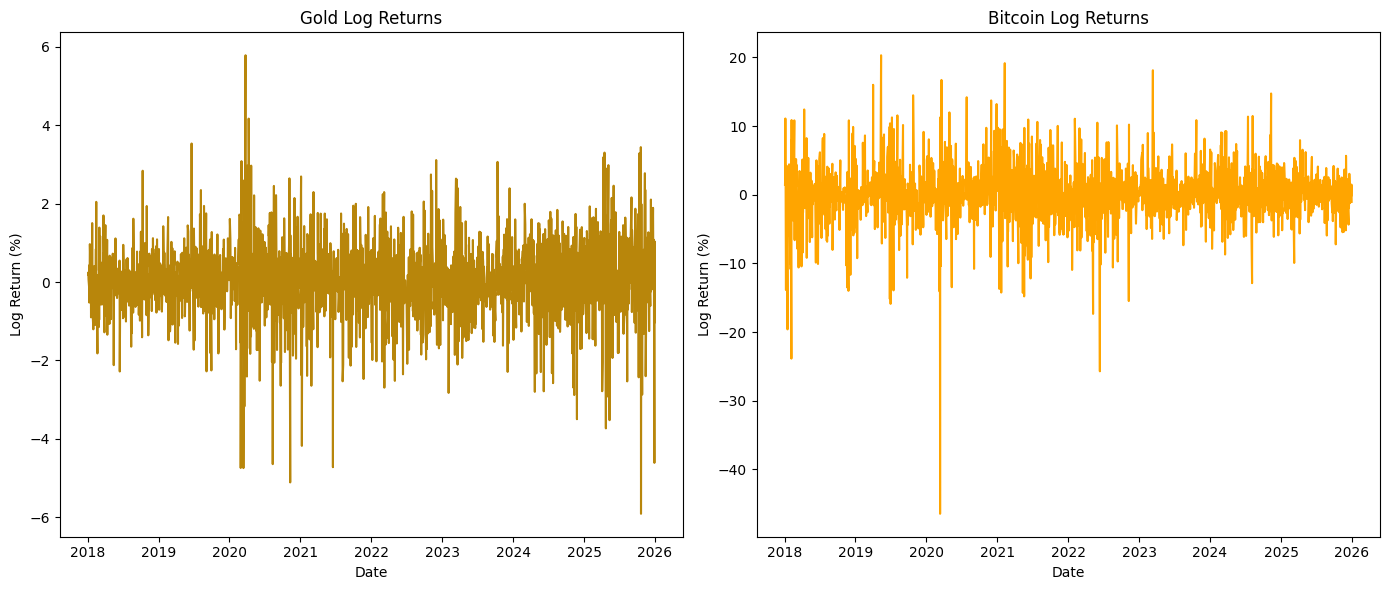

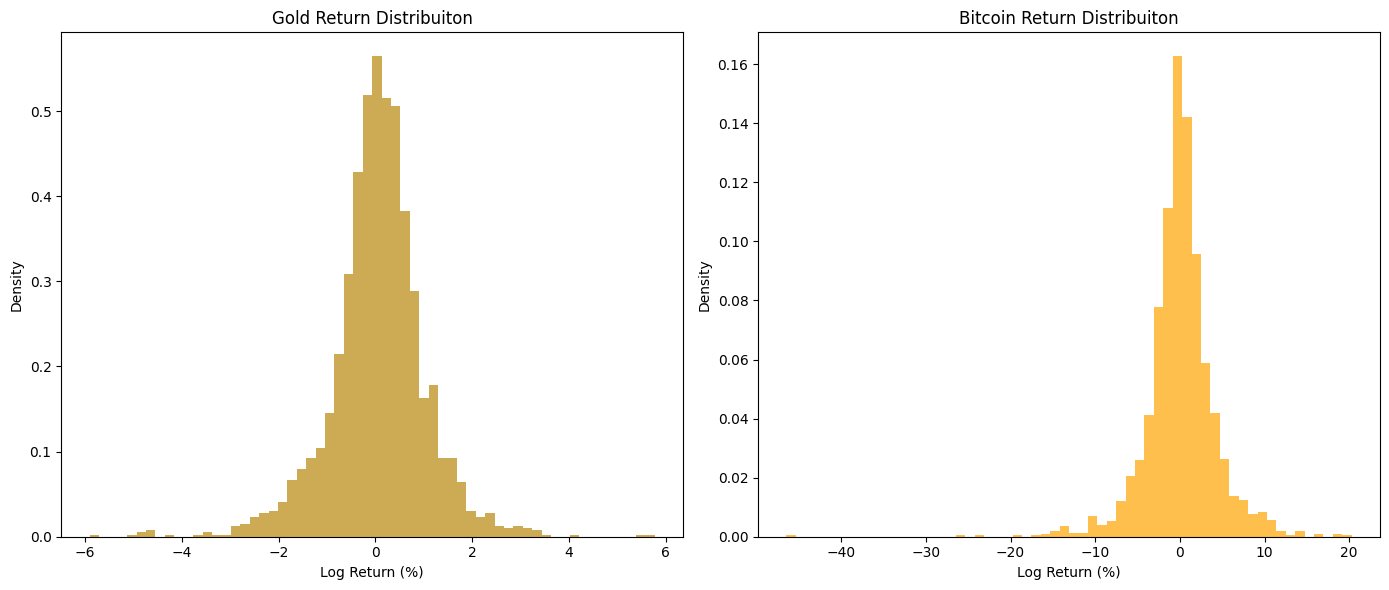

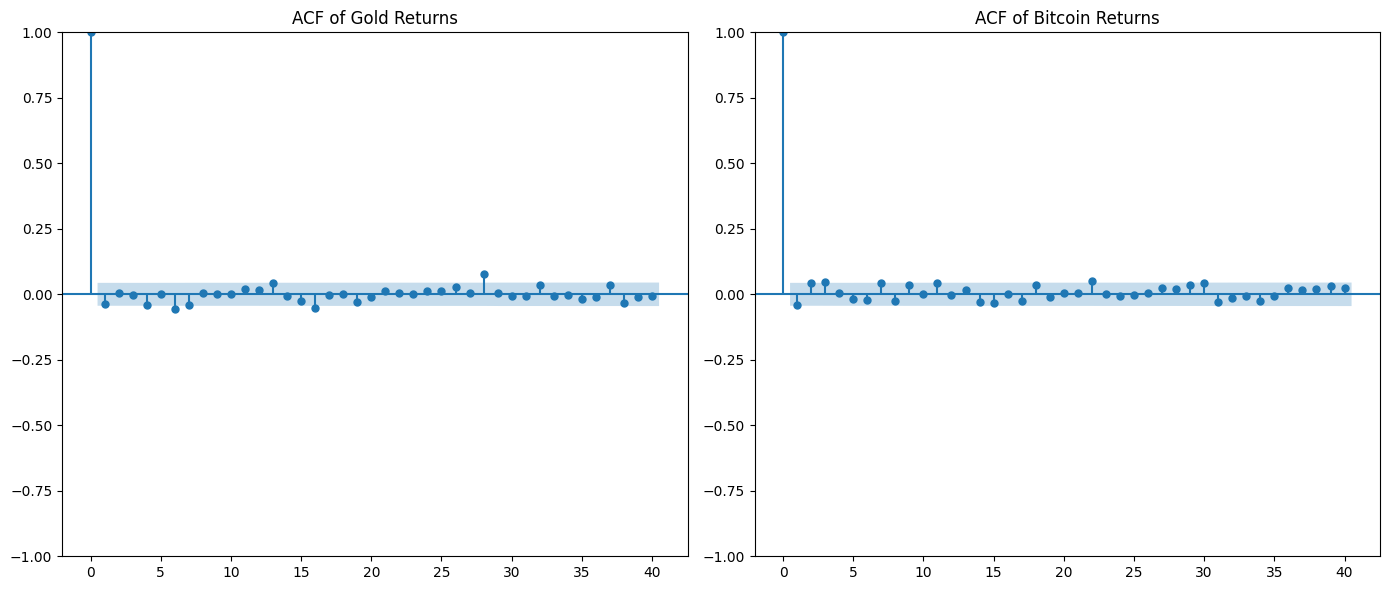

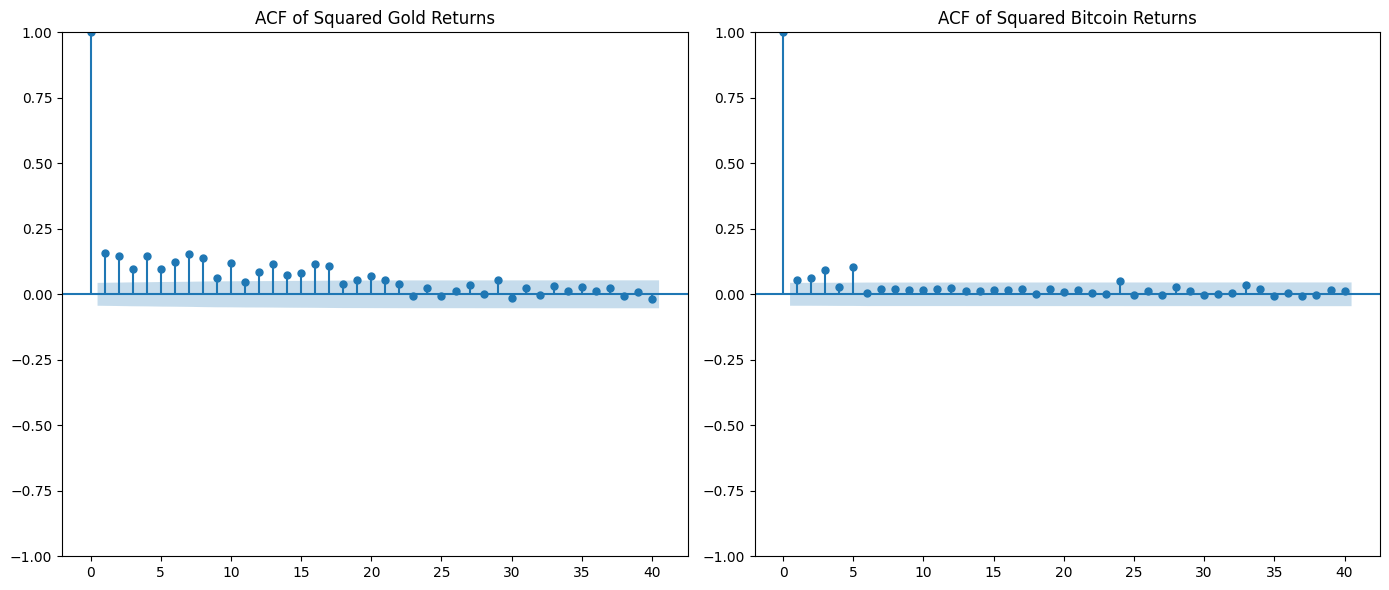

In [7]:
# exploratory plots
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# colors
colors = {
    "Gold": "darkgoldenrod",
    "Bitcoin": "orange"
}

# figure 1: Return Series
fig, ax = plt.subplots(1,2,figsize=(14,6))

for i, asset in enumerate(["Gold", "Bitcoin"]):
    ax[i].plot(returns_df.index, returns_df[asset], color=colors[asset])
    ax[i].set_title(f"{asset} Log Returns")
    ax[i].set_xlabel("Date")
    ax[i].set_ylabel("Log Return (%)")

plt.tight_layout()
plt.show()

# figure 2: Return Distribution

fig, ax = plt.subplots(1,2,figsize=(14,6))

for i, asset in enumerate(["Gold", "Bitcoin"]):
    ax[i].hist(returns_df[asset], bins=60, density=True, alpha=0.7, color=colors[asset])
    ax[i].set_title(f"{asset} Return Distribuiton")
    ax[i].set_xlabel("Log Return (%)")
    ax[i].set_ylabel("Density")

plt.tight_layout()
plt.show()

# figure 3: ACF of returns

fig, ax = plt.subplots(1,2,figsize=(14,6))

plot_acf(returns_df["Gold"], lags=40, ax=ax[0])
ax[0].set_title(f"ACF of Gold Returns")

plot_acf(returns_df["Bitcoin"], lags=40, ax=ax[1])
ax[1].set_title(f"ACF of Bitcoin Returns")

plt.tight_layout()
plt.show()


# figure 4: ACF of squared returns

fig, ax = plt.subplots(1,2, figsize=(14,6))

plot_acf(returns_df["Gold"] ** 2, lags=40, ax=ax[0])
ax[0].set_title(f"ACF of Squared Gold Returns")

plot_acf(returns_df[asset] ** 2, lags=40, ax=ax[1])
ax[1].set_title(f"ACF of Squared Bitcoin Returns")

plt.tight_layout()
plt.show()

ACF helps identify MA terms.
PACF helps identify AR terms.

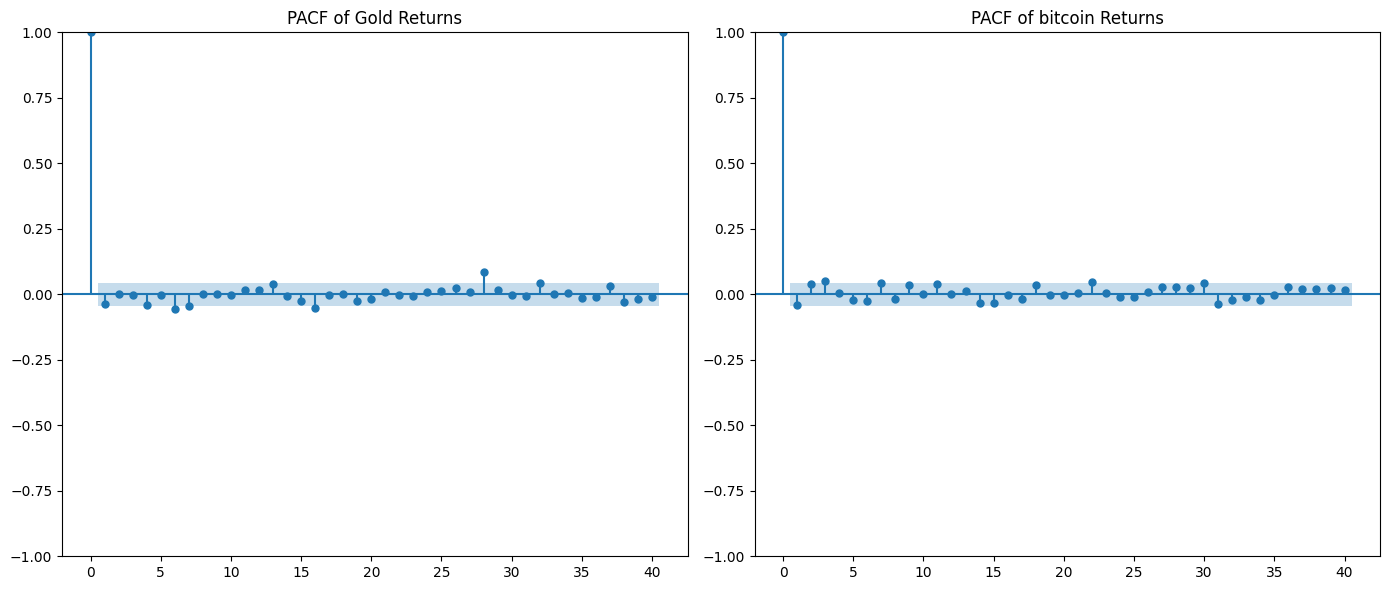

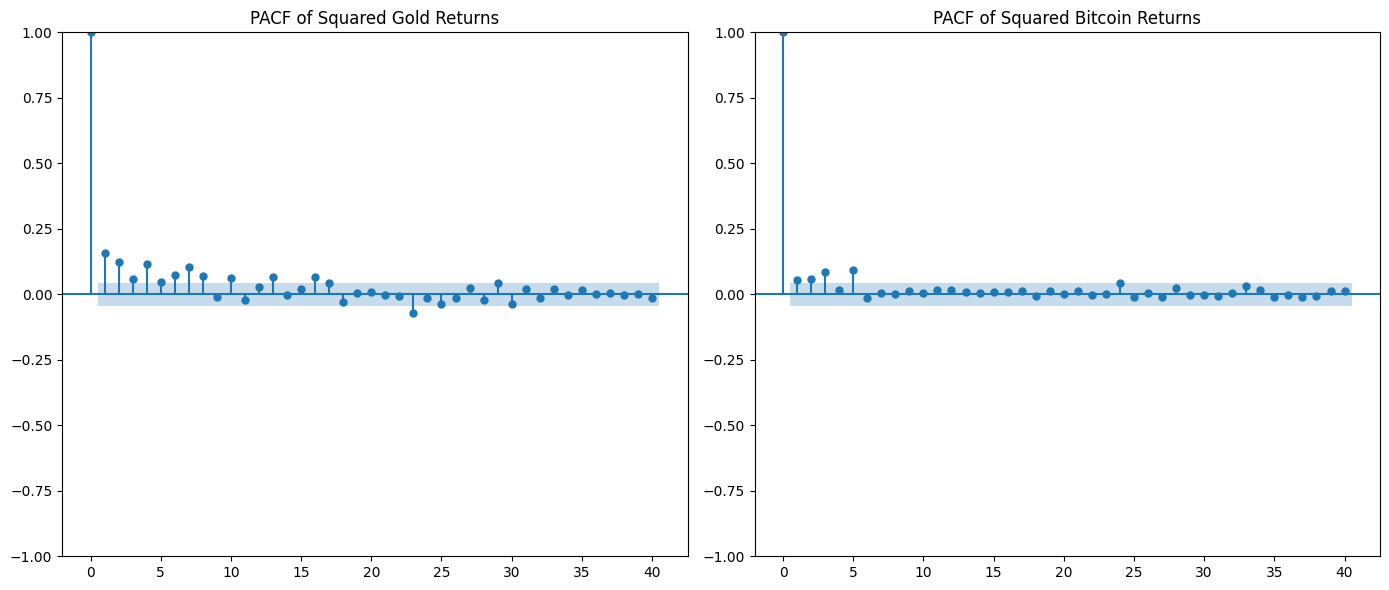

In [9]:
from statsmodels.graphics.tsaplots import plot_pacf
import matplotlib.pyplot as plt

# PACF of reutrns

fig, ax = plt.subplots(1,2,figsize=(14,6))

plot_pacf(
    returns_df["Gold"],
    lags=40,
    method="ywm",
    ax=ax[0]
)

ax[0].set_title("PACF of Gold Returns")

plot_pacf(
    returns_df["Bitcoin"],
    lags=40,
    method="ywm",
    ax=ax[1]
)

ax[1].set_title("PACF of bitcoin Returns")

plt.tight_layout()
plt.show()

# PACF of Squared Returns

fig, ax = plt.subplots(1, 2, figsize=(14,6))

plot_pacf(
    returns_df["Gold"]**2,
    lags=40,
    method="ywm",
    ax=ax[0]
)

ax[0].set_title("PACF of Squared Gold Returns")

plot_pacf(
    returns_df["Bitcoin"]**2,
    lags=40,
    method="ywm",
    ax=ax[1]
)

ax[1].set_title("PACF of Squared Bitcoin Returns")

plt.tight_layout()
plt.show()

In [ ]:
pip install arch

In [10]:
import warnings
import pandas as pd

from arch import arch_model

warnings.filterwarnings("ignore")


# Candidate Models

mean_models = [
    ("Constant Mean", None),
    ("AR(1)", 1)
]

dists = [
    "normal",
    "t"
]

results = []

# Gold + Bitcoin

for asset in ["Gold", "Bitcoin"]:

    y = returns_df[asset]

    for mean_name, lag in mean_models:

        for dist in dists:

            try:

                if lag is None:

                    model = arch_model(
                        y,
                        mean="Constant",
                        vol="GARCH",
                        p=1,
                        q=1,
                        dist=dist
                    )

                else:

                    model = arch_model(
                        y,
                        mean="AR",
                        lags=lag,
                        vol="GARCH",
                        p=1,
                        q=1,
                        dist=dist
                    )

                res = model.fit(disp="off")

                results.append({
                    "Asset": asset,
                    "Mean Model": mean_name,
                    "Distribution": dist,
                    "AIC": res.aic,
                    "BIC": res.bic,
                    "LogLik": res.loglikelihood
                })

            except Exception as e:

                print(asset, mean_name, dist, e)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["Asset", "AIC"]
)

print(results_df)

     Asset     Mean Model Distribution           AIC           BIC  \
7  Bitcoin          AR(1)            t  10722.107680  10755.743020   
5  Bitcoin  Constant Mean            t  10731.473200  10759.505137   
6  Bitcoin          AR(1)       normal  11164.135756  11192.165206   
4  Bitcoin  Constant Mean       normal  11169.078900  11191.504450   
3     Gold          AR(1)            t   5290.446571   5324.081911   
1     Gold  Constant Mean            t   5293.966019   5321.997956   
2     Gold          AR(1)       normal   5460.129233   5488.158683   
0     Gold  Constant Mean       normal   5464.140352   5486.565901   

        LogLik  
7 -5355.053840  
5 -5360.736600  
6 -5577.067878  
4 -5580.539450  
3 -2639.223286  
1 -2641.983010  
2 -2725.064616  
0 -2728.070176  


Model comparison based on AIC and BIC strongly favors Student-t innovations over Gaussian innovations for both Gold and Bitcoin returns. Among the candidate mean specifications, AR(1) provides the best overall fit, although the improvement over a constant mean is modest for Gold and more pronounced for Bitcoin. Consequently, AR(1)-GARCH(1,1) with Student-t innovations is selected as the benchmark specification.

In [11]:
# GARCH parameters
import warnings
import pandas as pd

from arch import arch_model

warnings.filterwarnings("ignore")

results = []

garch_specs = [
    (1,1),
    (1,2),
    (2,1)
]

for asset in ["Gold", "Bitcoin"]:

    y = returns_df[asset]

    for p,q in garch_specs:

        try:

            model = arch_model(
                y,
                mean="AR",
                lags = 1,
                vol="GARCH",
                p=p,
                q=q,
                dist="t"
            )

            res = model.fit(disp="off")

            results.append({
                "Asset": asset,
                "GARCH": f"({p},{q})",
                "AIC": res.aic,
                "BIC": res.bic,
                "LogLik": res.loglikelihood
            })

        except Exception as e:
            print(asset, p, q, e)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["Asset", "AIC"]
)

print(results_df)

     Asset  GARCH           AIC           BIC       LogLik
3  Bitcoin  (1,1)  10722.107680  10755.743020 -5355.053840
4  Bitcoin  (1,2)  10723.997541  10763.238771 -5354.998771
5  Bitcoin  (2,1)  10724.107680  10763.348910 -5355.053840
0     Gold  (1,1)   5290.446571   5324.081911 -2639.223286
2     Gold  (2,1)   5290.959335   5330.200565 -2638.479668
1     Gold  (1,2)   5292.446571   5331.687801 -2639.223286


Alternative GARCH specifications including GARCH(1,2) and GARCH(2,1) were estimated and compared using the Akaike and Bayesian Information Criteria. For both Gold and Bitcoin returns, GARCH(1,1) achieved the lowest AIC values. Since the improvements from higher-order specifications were negligible, the parsimonious GARCH(1,1) specification was retained for subsequent analyses.

In [ ]:
import warnings
import pandas as pd

from arch import arch_model

warnings.filterwarnings("ignore")

for asset in ["Gold", "Bitcoin"]:

    y = returns_df[asset]

    specs = [

        ("GARCH", dict(
            vol="GARCH",
            p=1,
            q=1
        )),

        ("EGARCH", dict(
            vol="EGARCH",
            p=1,
            q=1
        )),

        ("GJR-GARCH", dict(
            vol="GARCH",
            p=1,
            o=1,
            q=1
        ))
    ]

    for model_name, kwargs in specs:

        try:

            model = arch_model(
                y,
                mean="AR",
                lags = 1,
                dist="t",
                **kwargs
            )

            res = model.fit(disp="off")

            results.append({
                "Asset": asset,
                "Model": model_name,
                "AIC": res.aic,
                "BIC": res.bic,
                "LogLik": res.loglikelihood
            })

        except Exception as e:
            
            print(asset, model_name, e)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["Asset", "AIC"]
)

print(results_df)

      Asset  GARCH           AIC           BIC       LogLik      Model
10  Bitcoin    NaN  10704.805020  10738.440360 -5346.402510     EGARCH
3   Bitcoin  (1,1)  10722.107680  10755.743020 -5355.053840        NaN
9   Bitcoin    NaN  10722.107680  10755.743020 -5355.053840      GARCH
4   Bitcoin  (1,2)  10723.997541  10763.238771 -5354.998771        NaN
11  Bitcoin    NaN  10724.105360  10763.346590 -5355.052680  GJR-GARCH
5   Bitcoin  (2,1)  10724.107680  10763.348910 -5355.053840        NaN
8      Gold    NaN   5278.937694   5318.178924 -2632.468847  GJR-GARCH
7      Gold    NaN   5285.427200   5319.062540 -2636.713600     EGARCH
0      Gold  (1,1)   5290.446571   5324.081911 -2639.223286        NaN
6      Gold    NaN   5290.446571   5324.081911 -2639.223286      GARCH
2      Gold  (2,1)   5290.959335   5330.200565 -2638.479668        NaN
1      Gold  (1,2)   5292.446571   5331.687801 -2639.223286        NaN


We'll fit:

Gold
AR(1)−GJR-GARCH(1,1)−t
Bitcoin
AR(1)−EGARCH(1,1)−t

and check whether anything remains unexplained.

In [ ]:
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

final_models = {

    "Gold": dict(
        mean="AR",
        lags = 1,
        vol="GARCH",
        p=1,
        o=1,
        q=1,
        dist="t"
    ),

    "Bitcoin": dict(
        mean="AR",
        lags=1,
        vol="EGARCH",
        p=1,
        q=1,
        dist="t"
    )
}

for asset, spec in final_models.items():

    print("\n")
    print("="*50)
    print(asset)
    print("="*50)

    model = arch_model(
        returns_df[asset],
        **spec
    )

    res = model.fit(disp="off")

    resid = res.std_resid.dropna()

    # ljung box on residuals

    lb_resid = acorr_ljungbox(
        resid,
        lags=[10,20],
        return_df=True
    )

    print("\nL-jung-Box (Standardized Residuals)")
    print(lb_resid)

    # ljung box on squared residuals

    lb_sq = acorr_ljungbox(
        resid**2,
        lags = [10,20],
        return_df = True
    )

    print("\nL-jung-Box (Squared Residuals)")
    print(lb_sq)

    # ARCH LM

    arch = het_arch(resid)

    print("\nARCH-LM")
    print("Statistic:", arch[0])
    print("p-value:", arch[1])



Gold

L-jung-Box (Standardized Residuals)
     lb_stat  lb_pvalue
10  4.295724   0.933022
20  9.760430   0.972311

L-jung-Box (Squared Residuals)
      lb_stat  lb_pvalue
10  11.807931   0.298117
20  16.292059   0.698348

ARCH-LM
Statistic: 11.730853885714154
p-value: 0.30347325820798765


Bitcoin

L-jung-Box (Standardized Residuals)
      lb_stat  lb_pvalue
10  21.364697   0.018689
20  35.463675   0.017769

L-jung-Box (Squared Residuals)
      lb_stat  lb_pvalue
10  18.157378   0.052366
20  22.020263   0.339412

ARCH-LM
Statistic: 18.592728543944894
p-value: 0.04575117456747079


In [ ]:
import warnings
import pandas as pd
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")

btc_results = []

btc_specs = {
    "AR(1)-EGARCH(1,1)-t": dict(
        mean="AR", lags=1, vol="EGARCH", p=1, q=1, dist="t"
    ),
    "AR(2)-EGARCH(1,1)-t": dict(
        mean="AR", lags=2, vol="EGARCH", p=1, q=1, dist="t"
    ),
    "AR(3)-EGARCH(1,1)-t": dict(
        mean="AR", lags=3, vol="EGARCH", p=1, q=1, dist="t"
    )
}

for name, spec in btc_specs.items():

    model = arch_model(returns_df["Bitcoin"], **spec)
    res = model.fit(disp="off")

    std_resid = res.std_resid.dropna()

    lb_resid_10 = acorr_ljungbox(std_resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
    lb_resid_20 = acorr_ljungbox(std_resid, lags=[20], return_df=True)["lb_pvalue"].iloc[0]

    lb_sq_10 = acorr_ljungbox(std_resid**2, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
    lb_sq_20 = acorr_ljungbox(std_resid**2, lags=[20], return_df=True)["lb_pvalue"].iloc[0]

    arch_p = het_arch(std_resid)[1]

    btc_results.append({
        "Model": name,
        "AIC": res.aic,
        "BIC": res.bic,
        "LogLik": res.loglikelihood,
        "LB Resid p10": lb_resid_10,
        "LB Resid p20": lb_resid_20,
        "LB Sq p10": lb_sq_10,
        "LB Sq p20": lb_sq_20,
        "ARCH-LM p": arch_p
    })


btc_diag_df = pd.DataFrame(btc_results).sort_values("AIC")

display(btc_diag_df)

,Model,AIC,BIC,LogLik,LB Resid p10,LB Resid p20,LB Sq p10,LB Sq p20,ARCH-LM p
2,"AR(3)-EGARCH(1,1)-t",10692.658722,10737.497878,-5338.329361,0.029808,0.026252,0.046120,0.314580,0.039314
1,"AR(2)-EGARCH(1,1)-t",10699.346284,10738.584030,-5342.673142,0.032974,0.028882,0.045675,0.311934,0.038789
0,"AR(1)-EGARCH(1,1)-t",10704.805020,10738.440360,-5346.402510,0.018689,0.017769,0.052366,0.339412,0.045751


AIC view

AIC strongly prefers:

AR(3)−EGARCH(1,1)−t

Difference:

10704.81−10692.66=12.15

That's a meaningful improvement.

Diagnostic view

Unfortunately:

Ljung-Box still < 0.05
ARCH-LM still < 0.05

for all models.

The improvement is modest.

Final models I would report
Gold
AR(1)−GJR-GARCH(1,1)−t
	​

Bitcoin
AR(3)−EGARCH(1,1)−t
	​


In [ ]:
from arch import arch_model

# GOLD - AR(1)-GJR-GARCH(1,1)-t

gold_model = arch_model(
    returns_df["Gold"],
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

gold_res = gold_model.fit(disp="off")

print(gold_res.summary())

# BITCOIN - AR(3)-EGARCH(1,1)-t

btc_model = arch_model(
    returns_df["Bitcoin"],
    mean = "AR",
    lags = 3,
    vol = "EGARCH",
    p=1,
    q=1,
    dist="t"
)

btc_res = btc_model.fit(disp="off")

print(btc_res.summary())

                            AR - GJR-GARCH Model Results                            
Dep. Variable:                         Gold   R-squared:                       0.001
Mean Model:                              AR   Adj. R-squared:                  0.001
Vol Model:                        GJR-GARCH   Log-Likelihood:               -2632.47
Distribution:      Standardized Student's t   AIC:                           5278.94
Method:                  Maximum Likelihood   BIC:                           5318.18
                                              No. Observations:                 2010
Date:                      Sun, Jun 21 2026   Df Residuals:                     2008
Time:                              15:33:43   Df Model:                            2
                                  Mean Model                                  
                 coef    std err          t      P>|t|        95.0% Conf. Int.
-----------------------------------------------------------------------------

In [ ]:
# GOLD

gold_fc = gold_res.forecast(horizon=1)

print("Gold")

print(
    "Forecast Mean:",
    gold_fc.mean.iloc[-1,0]
)

print(
    "Forecast Variance:",
    gold_fc.variance.iloc[-1,0]
)

print(
    "Forecast Volatility:",
    gold_fc.variance.iloc[-1,0]**0.5
)


# BITCOIN

btc_fc = btc_res.forecast(horizon=1)

print("\nBitcoin")

print(
    "Forecast Mean:",
    btc_fc.mean.iloc[-1,0]
)

print(
    "Forecast Variance:",
    btc_fc.variance.iloc[-1,0]
)

print(
    "Forecast Volatility:",
    btc_fc.variance.iloc[-1,0]**0.5
)

Gold
Forecast Mean: 0.12342200897449299
Forecast Variance: 1.6390332377167953
Forecast Volatility: 1.280247334586874

Bitcoin
Forecast Mean: 0.14578439506753788
Forecast Variance: 8.388910292028719
Forecast Volatility: 2.896361560998336


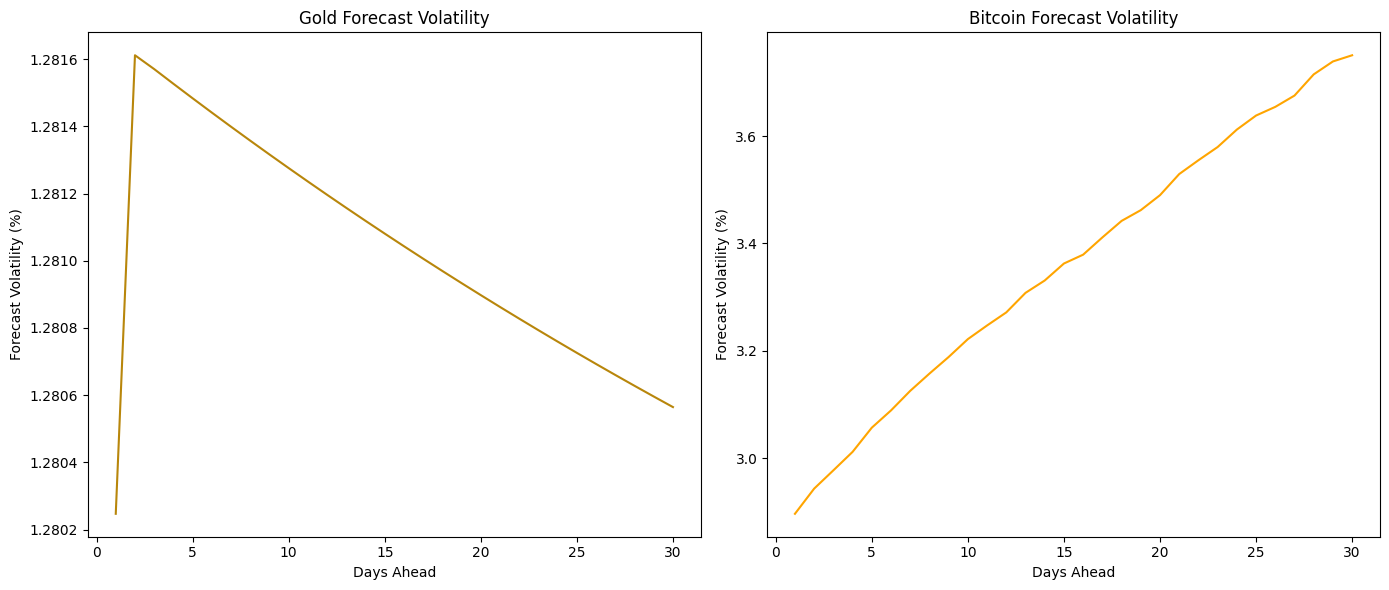

In [ ]:
import matplotlib.pyplot as plt

# Gold

gold_fc = gold_res.forecast(
    horizon=30,
    reindex=False
)

gold_vol = gold_fc.variance.values[-1]**0.5

# Bitcoin

btc_fc = btc_res.forecast(
    horizon=30,
    method="Simulation",
    simulations=5000,
    reindex=False
)

btc_vol = btc_fc.variance.values[-1]**0.5

# Plot

fig, ax = plt.subplots(
    1,
    2,
    figsize=(14,6)
)

ax[0].plot(
    range(1,31),
    gold_vol,
    color="darkgoldenrod"
)

ax[0].set_title(
    "Gold Forecast Volatility"
)

ax[0].set_xlabel(
    "Days Ahead"
)

ax[0].set_ylabel(
    "Forecast Volatility (%)"
)

ax[1].plot(
    range(1,31),
    btc_vol,
    color="orange"
)

ax[1].set_title(
    "Bitcoin Forecast Volatility"
)

ax[1].set_xlabel(
    "Days Ahead"
)

ax[1].set_ylabel(
    "Forecast Volatility (%)"
)

plt.tight_layout()
plt.show()

In [ ]:
print(gold_vol[:10])
print()
print(btc_vol[:10])



[1.28024733 1.28161127 1.28157013 1.28152645 1.28148332 1.28144073
 1.28139868 1.28135715 1.28131615 1.28127566]

[2.89636156 2.94326348 2.9773191  3.01173803 3.05679039 3.08893257
 3.12539342 3.15752203 3.18846986 3.22175461]


In [ ]:
print(gold_vol[-5:])
print()
print(btc_vol[-5:])

[1.28069292 1.28066027 1.28062803 1.2805962  1.28056476]

[3.65437601 3.67542457 3.71490733 3.7389844  3.75051902]


In [ ]:
print("Gold mean:", gold_fc.mean.iloc[-1,0])
print("Gold vol :", gold_fc.variance.iloc[-1,0]**0.5)

print("BTC mean :", btc_fc.mean.iloc[-1,0])
print("BTC vol  :", btc_fc.variance.iloc[-1,0]**0.5)

Gold mean: 0.12342200897449299
Gold vol : 1.280247334586874
BTC mean : 0.14578439506753788
BTC vol  : 2.896361560998416


While the AR(3)-EGARCH(1,1)-Student-t model substantially reduces serial dependence and volatility clustering, residual diagnostics indicate that a small degree of dependence remains. This finding is consistent with the complex and evolving nature of cryptocurrency markets and suggests that higher-order nonlinear or regime-switching models may provide additional explanatory power.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Monte Carlo Settings

HORIZON = 30
N_SIM = 5000

# GOLD Simulation

gold_mc = gold_res.forecast(
    horizon=HORIZON,
    method="simulation",
    simulations=N_SIM,
    reindex=False
)

gold_paths  = gold_mc.simulations.values[-1] # shape: simulations * horizon

# BITCOIN simualtion

btc_mc = btc_res.forecast(
    horizon=HORIZON,
    method="simulation",
    simulations=N_SIM,
    reindex=False
)

btc_paths  = btc_mc.simulations.values[-1] 

print("Gold paths shape:", gold_paths.shape)
print("Bitcoin paths shape: ", btc_paths.shape)

Gold paths shape: (5000, 30)
Bitcoin paths shape:  (5000, 30)


In [ ]:
# cumulative return paths in percent approximation
gold_cum_paths = np.cumsum(gold_paths, axis=1)
btc_cum_paths = np.cumsum(btc_paths, axis=1)

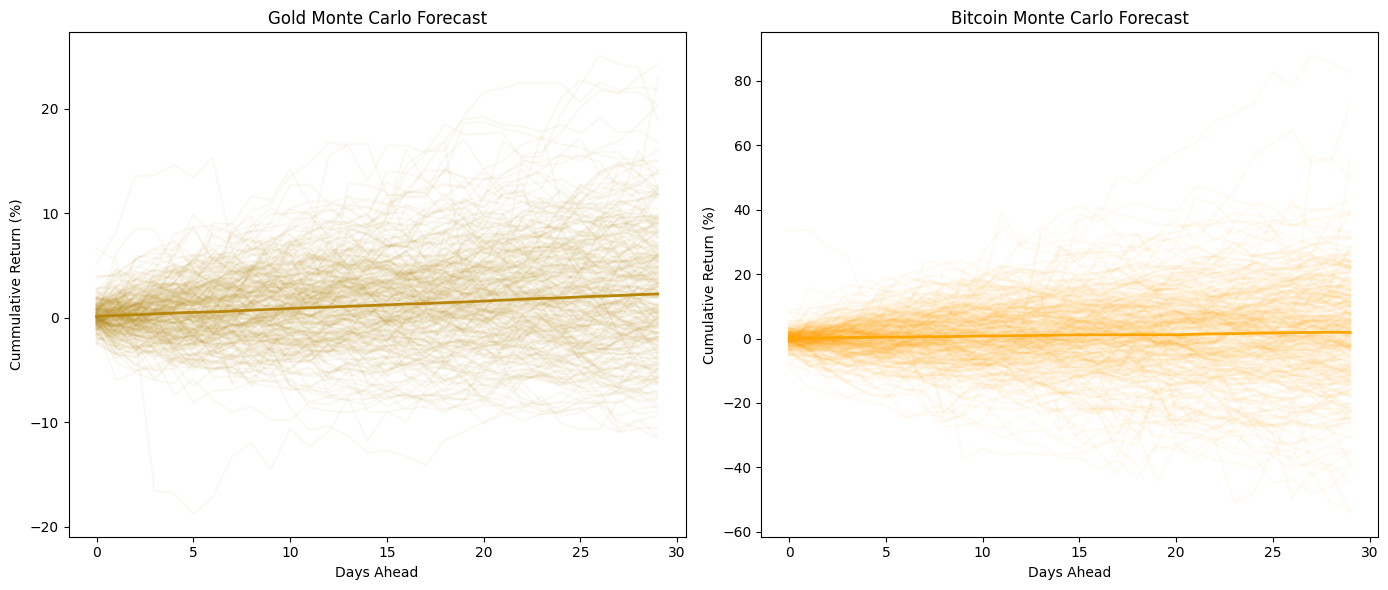

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14,6))

# gold
ax[0].plot(gold_cum_paths[:300].T, color="darkgoldenrod", alpha=0.05)
ax[0].plot(np.mean(gold_cum_paths, axis=0), color="darkgoldenrod", linewidth=2)
ax[0].set_title("Gold Monte Carlo Forecast")
ax[0].set_xlabel("Days Ahead")
ax[0].set_ylabel("Cummulative Return (%)")

# bitcoin
ax[1].plot(btc_cum_paths[:300].T, color="orange", alpha=0.05)
ax[1].plot(np.mean(btc_cum_paths, axis=0), color="orange", linewidth=2)
ax[1].set_title("Bitcoin Monte Carlo Forecast")
ax[1].set_xlabel("Days Ahead")
ax[1].set_ylabel("Cumulative Return (%)")

plt.tight_layout()
plt.show()

In [ ]:
gold_final = gold_cum_paths[:, -1]
btc_final = btc_cum_paths[:, -1]

summary_mc = {
    "Gold": {
        "Mean 30D Return": np.mean(gold_final),
        "Median 30D Return": np.median(gold_final),
        "5% Quantile": np.percentile(gold_final, 5),
        "1% Quantile": np.percentile(gold_final, 1),
        "95% Quantile": np.percentile(gold_final, 95),
        "99% Quantile": np.percentile(gold_final, 99),
    },
    "Bitcoin": {
        "Mean 30D Return": np.mean(btc_final),
        "Median 30D Return": np.median(btc_final),
        "5% 30D Return": np.percentile(btc_final, 5),
        "1% 30D Return": np.percentile(btc_final, 1),
        "95% 30D Return": np.percentile(btc_final, 95),
        "99% 30D Return": np.percentile(btc_final, 99),
    }
}

pd.DataFrame(summary_mc).T

,Mean 30D Return,Median 30D Return,5% Quantile,1% Quantile,95% Quantile,99% Quantile,5% 30D Return,1% 30D Return,95% 30D Return,99% 30D Return
Gold,2.263695,2.055049,-7.52722,-12.421273,12.840436,20.138835,NaN,NaN,NaN,NaN
Bitcoin,1.871759,2.135486,NaN,NaN,NaN,NaN,-25.689299,-45.585843,29.694233,48.01023


In [ ]:
print(np.mean(gold_paths))
print(np.mean(btc_paths))

print(np.mean(gold_paths[:,0]))
print(np.mean(btc_paths[:,0]))

0.07545648381229934
0.06239195146118131
0.13079431516929327
0.10438213333272793


In [ ]:
import pandas as pd
import numpy as np

def monte_carlo_var_es(final_returns, asset_name):
    """
    final_returns: simulated 30-day cumulative returns in percent.
    """

    var_95 = np.percentile(final_returns, 5)
    var_99 = np.percentile(final_returns, 1)

    es_95 = final_returns[final_returns <= var_95].mean()
    es_99 = final_returns[final_returns <= var_99].mean()

    return {
        "Asset": asset_name,
        "Mean 30D Return": final_returns.mean(),
        "Median 30D Return": np.median(final_returns),
        "VaR 95%": var_95,
        "VaR 99%": var_99,
        "ES 95%": es_95,
        "ES 99%": es_99
    }


risk_results = [
    monte_carlo_var_es(gold_final, "Gold"),
    monte_carlo_var_es(btc_final, "Bitcoin")
]

risk_df = pd.DataFrame(risk_results)

display(risk_df)

,Asset,Mean 30D Return,Median 30D Return,VaR 95%,VaR 99%,ES 95%,ES 99%
0,Gold,2.263695,2.055049,-7.527220,-12.421273,-10.624551,-16.080506
1,Bitcoin,1.871759,2.135486,-25.689299,-45.585843,-42.054302,-77.707807


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import genpareto

# Define losses

losses_df = -returns_df.copy()

# EVT function

def evt_pot_gpd(losses, asset_name, threshold_quantile=0.95):
    """
    POT-GPD EVT estimation.
    losses are positive when returns are negative.
    """

    losses = losses.dropna()

    # Threshold
    u = np.quantile(losses, threshold_quantile)

    # Exceedances over threshold

    exceedances = losses[losses > u] - u

    # Fit GPD
    shape, loc, scale = genpareto.fit(exceedances, floc=0)

    n = len(losses)
    nu = len(exceedances)

    def evt_var(alpha):
        """
        EVT VaR at confidence level alpha.
        Example: alpha=0.95 or 0.99
        """

        if shape != 0:
            var = u + (scale / shape) * (((n / nu) * (1 - alpha)) ** (-shape) - 1)
        else:
            var = u - scale * np.log((n / nu) * (1 - alpha))

        return var

    def evt_es(alpha):
        """
        EVT Expected Shortfall.
        Valid when shape < 1.
        """

        var = evt_var(alpha)

        if shape < 1:
            es = (var + scale - shape * u) / (1 - shape)
        else:
            es = np.nan

        return es

    results = {
        "Asset": asset_name,
        "Threshold q": threshold_quantile,
        "Threshold u": u,
        "Exceedances": nu,
        "Shape xi": shape,
        "Scale beta": scale,
        "EVT VaR 95%": evt_var(0.95),
        "EVT VaR 99%": evt_var(0.99),
        "EVT ES 95%": evt_es(0.95),
        "EVT ES 99%": evt_es(0.99)
    }

    return results, exceedances, u, shape, scale


# Run EVT

gold_evt, gold_exceed, gold_u, gold_xi, gold_beta = evt_pot_gpd(
    losses_df["Gold"],
    "Gold",
    threshold_quantile=0.95
)

btc_evt, btc_exceed, btc_u, btc_xi, btc_beta = evt_pot_gpd(
    losses_df["Bitcoin"],
    "Bitcoin",
    threshold_quantile=0.95
)

evt_df = pd.DataFrame([gold_evt, btc_evt])

display(evt_df)

,Asset,Threshold q,Threshold u,Exceedances,Shape xi,Scale beta,EVT VaR 95%,EVT VaR 99%,EVT ES 95%,EVT ES 99%
0,Gold,0.95,1.601324,101,0.145277,0.658983,1.604268,2.799882,2.375758,3.774590
1,Bitcoin,0.95,6.139950,101,0.241217,2.924723,6.153017,11.910762,10.011664,17.599797


In [ ]:
print("Gold threshold:", gold_u)
print("Gold max loss :", losses_df["Gold"].max())

print()

print("BTC threshold :", btc_u)
print("BTC max loss  :", losses_df["Bitcoin"].max())

Gold threshold: 1.6013241701118464
Gold max loss : 5.906203554004988

BTC threshold : 6.139949544417101
BTC max loss  : 46.4730175339773


In [ ]:
print("Gold exceedances:", len(gold_exceed))
print("BTC exceedances :", len(btc_exceed))

Gold exceedances: 101
BTC exceedances : 101


In [ ]:
def empirical_var_es(losses, asset_name):
    losses = losses.dropna()

    var_95 = np.percentile(losses, 95)
    var_99 = np.percentile(losses, 99)

    es_95 = losses[losses >= var_95].mean()
    es_99 = losses[losses >= var_99].mean()

    return {
        "Asset": asset_name,
        "Empirical VaR 95%": var_95,
        "Empirical VaR 99%": var_99,
        "Empirical ES 95%": es_95,
        "Empirical ES 99%": es_99
    }

empirical_df = pd.DataFrame([
    empirical_var_es(losses_df["Gold"], "Gold"),
    empirical_var_es(losses_df["Bitcoin"], "Bitcoin")
])

comparison_df = empirical_df.merge(
    evt_df[[
        "Asset",
        "EVT VaR 95%",
        "EVT VaR 99%",
        "EVT ES 95%",
        "EVT ES 99%"
    ]],
    on="Asset"
)

display(comparison_df)

,Asset,Empirical VaR 95%,Empirical VaR 99%,Empirical ES 95%,Empirical ES 99%,EVT VaR 95%,EVT VaR 99%,EVT ES 95%,EVT ES 99%
0,Gold,1.601324,2.692275,2.369947,3.730093,1.604268,2.799882,2.375758,3.774590
1,Bitcoin,6.139950,12.190872,9.984492,17.060626,6.153017,11.910762,10.011664,17.599797


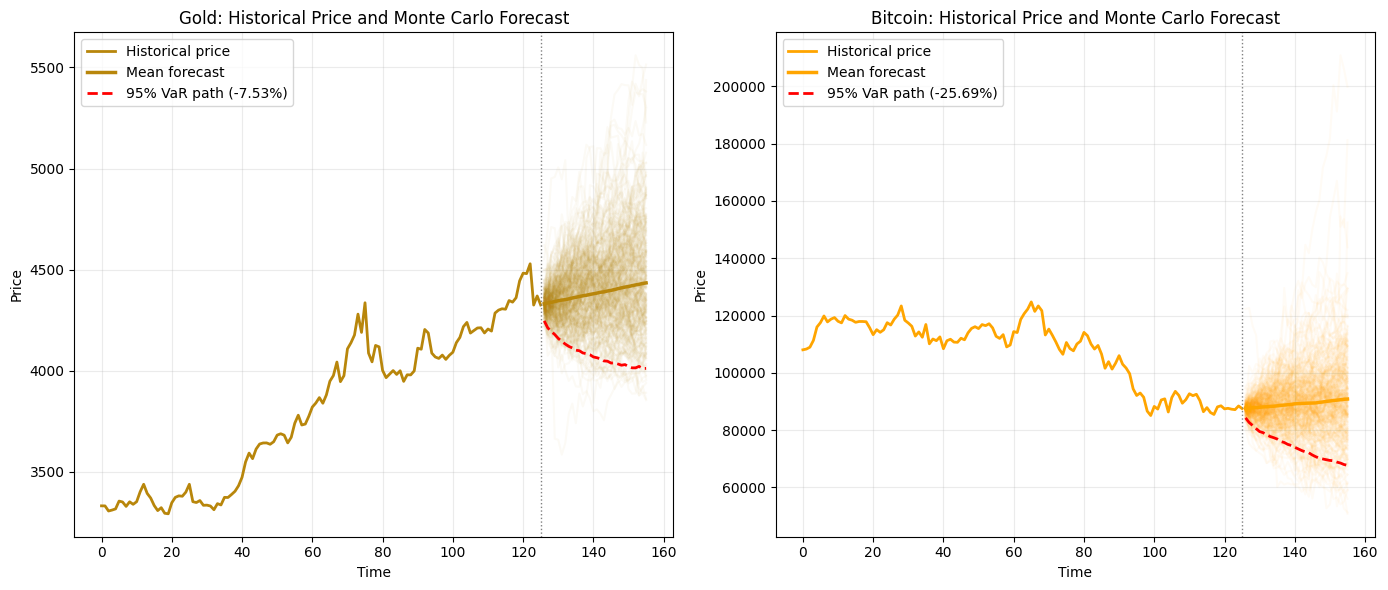

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_price_mc(asset, prices, sim_returns, color, title):
    last_6m = prices[asset].iloc[-126:]
    last_price = last_6m.iloc[-1]

    # Convert simulated returns (%) to price paths
    price_paths = last_price * np.exp(np.cumsum(sim_returns / 100, axis=1))

    mean_path = price_paths.mean(axis=0)
    var95_path = np.percentile(price_paths, 5, axis=0)

    var95_return = np.percentile(np.cumsum(sim_returns, axis=1)[:, -1], 5)

    hist_x = np.arange(len(last_6m))
    future_x = np.arange(len(last_6m), len(last_6m) + sim_returns.shape[1])

    ax.plot(hist_x, last_6m.values, color=color, linewidth=2, label="Historical price")

    ax.plot(future_x, price_paths[:300].T, color=color, alpha=0.04)

    ax.plot(
        future_x,
        mean_path,
        color=color,
        linewidth=2.5,
        linestyle="-",
        label="Mean forecast"
    )

    ax.plot(
        future_x,
        var95_path,
        color="red",
        linewidth=2,
        linestyle="--",
        label=f"95% VaR path ({var95_return:.2f}%)"
    )

    ax.axvline(len(last_6m)-1, color="gray", linestyle=":", linewidth=1)

    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel("Price")
    ax.legend()
    ax.grid(alpha=0.25)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
plot_price_mc("Gold", prices_df, gold_paths, "darkgoldenrod", "Gold: Historical Price and Monte Carlo Forecast")

ax = axes[1]
plot_price_mc("Bitcoin", prices_df, btc_paths, "orange", "Bitcoin: Historical Price and Monte Carlo Forecast")

plt.tight_layout()
plt.show()

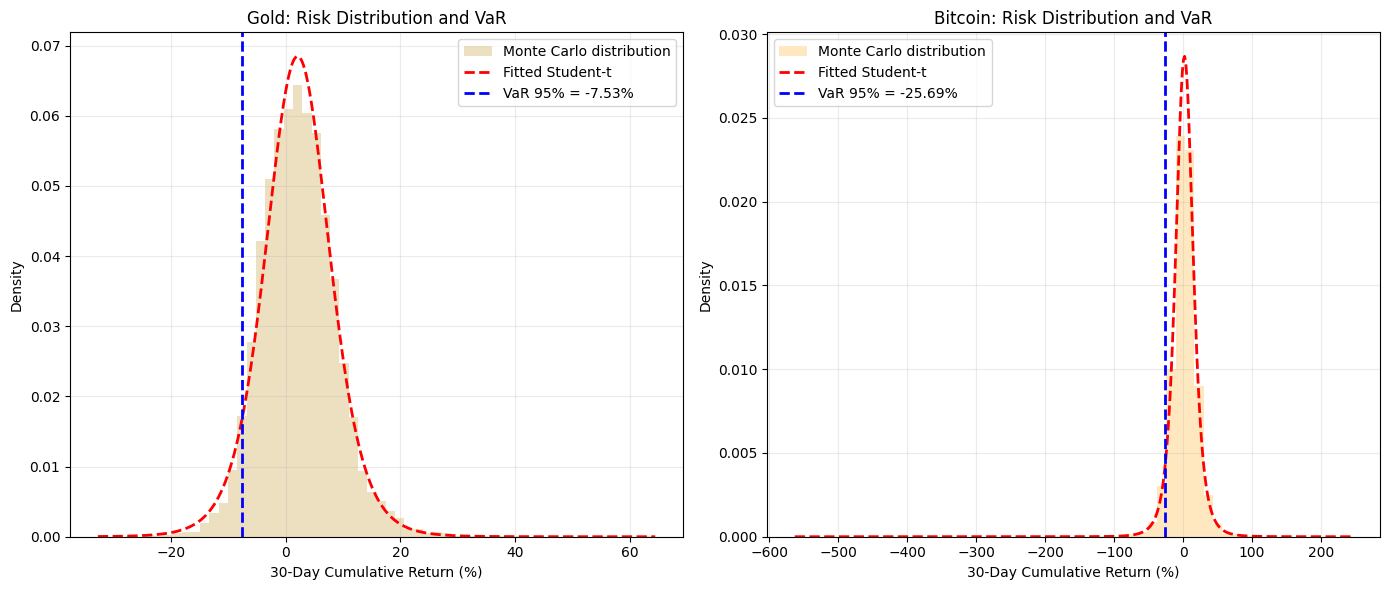

In [ ]:
from scipy.stats import t

def plot_risk_distribution(final_returns, color, title):
    x = final_returns

    # Fit Student-t distribution
    df, loc, scale = t.fit(x)

    x_grid = np.linspace(x.min(), x.max(), 500)
    pdf = t.pdf(x_grid, df, loc=loc, scale=scale)

    var95 = np.percentile(x, 5)

    ax.hist(
        x,
        bins=60,
        density=True,
        alpha=0.25,
        color=color,
        label="Monte Carlo distribution"
    )

    ax.plot(
        x_grid,
        pdf,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Fitted Student-t"
    )

    ax.axvline(
        var95,
        color="blue",
        linestyle="--",
        linewidth=2,
        label=f"VaR 95% = {var95:.2f}%"
    )

    ax.set_title(title)
    ax.set_xlabel("30-Day Cumulative Return (%)")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.25)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
plot_risk_distribution(gold_final, "darkgoldenrod", "Gold: Risk Distribution and VaR")

ax = axes[1]
plot_risk_distribution(btc_final, "orange", "Bitcoin: Risk Distribution and VaR")

plt.tight_layout()
plt.show()

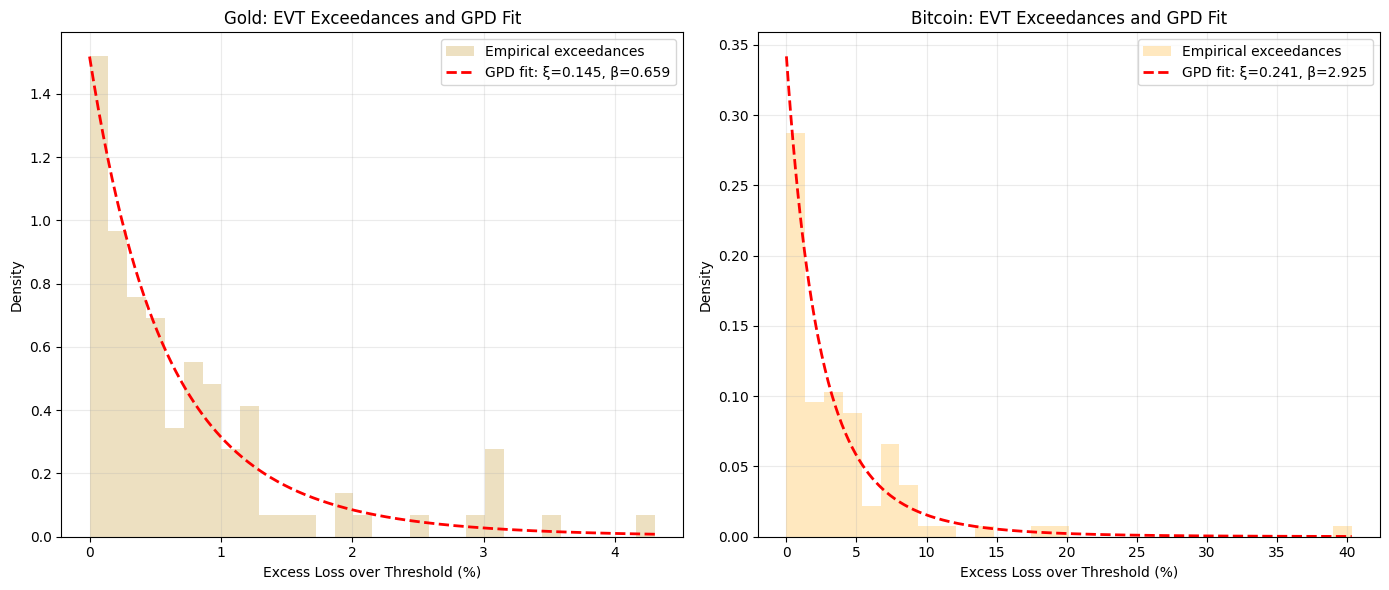

In [ ]:
from scipy.stats import genpareto

def plot_evt_gpd(exceedances, xi, beta, color, title):
    x = np.asarray(exceedances)

    x_grid = np.linspace(0, x.max(), 500)
    gpd_pdf = genpareto.pdf(x_grid, c=xi, loc=0, scale=beta)

    ax.hist(
        x,
        bins=30,
        density=True,
        alpha=0.25,
        color=color,
        label="Empirical exceedances"
    )

    ax.plot(
        x_grid,
        gpd_pdf,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"GPD fit: ξ={xi:.3f}, β={beta:.3f}"
    )

    ax.set_title(title)
    ax.set_xlabel("Excess Loss over Threshold (%)")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.25)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
plot_evt_gpd(gold_exceed, gold_xi, gold_beta, "darkgoldenrod", "Gold: EVT Exceedances and GPD Fit")

ax = axes[1]
plot_evt_gpd(btc_exceed, btc_xi, btc_beta, "orange", "Bitcoin: EVT Exceedances and GPD Fit")

plt.tight_layout()
plt.show()

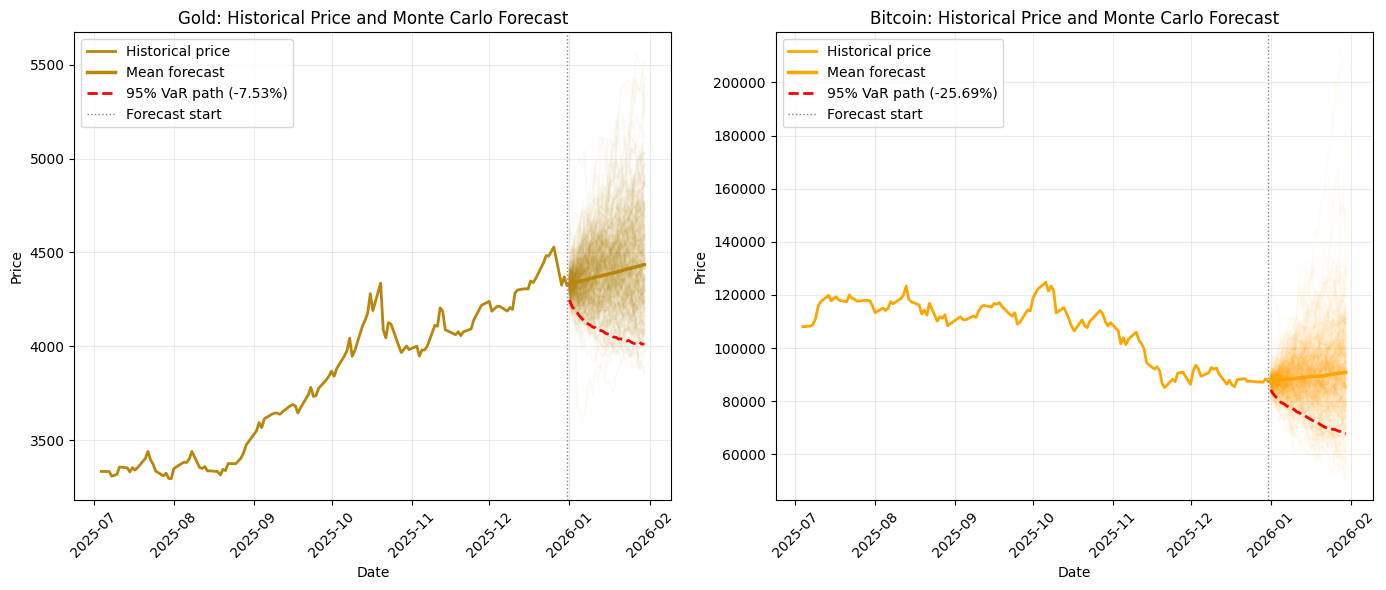

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_price_mc_with_dates(asset, prices, sim_returns, color, title):
    last_6m = prices[asset].iloc[-126:]
    last_price = last_6m.iloc[-1]
    last_date = last_6m.index[-1]

    # Forecast dates: next 30 calendar days
    future_dates = pd.date_range(
        start=last_date + pd.Timedelta(days=1),
        periods=sim_returns.shape[1],
        freq="D"
    )

    # Convert simulated returns (%) to price paths
    price_paths = last_price * np.exp(
        np.cumsum(sim_returns / 100, axis=1)
    )

    mean_path = price_paths.mean(axis=0)
    var95_path = np.percentile(price_paths, 5, axis=0)

    var95_return = np.percentile(
        np.cumsum(sim_returns, axis=1)[:, -1],
        5
    )

    ax.plot(
        last_6m.index,
        last_6m.values,
        color=color,
        linewidth=2,
        label="Historical price"
    )

    ax.plot(
        future_dates,
        price_paths[:300].T,
        color=color,
        alpha=0.04
    )

    ax.plot(
        future_dates,
        mean_path,
        color=color,
        linewidth=2.5,
        label="Mean forecast"
    )

    ax.plot(
        future_dates,
        var95_path,
        color="red",
        linewidth=2,
        linestyle="--",
        label=f"95% VaR path ({var95_return:.2f}%)"
    )

    ax.axvline(
        last_date,
        color="grey",
        linestyle=":",
        linewidth=1,
        label="Forecast start"
    )

    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Price")

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    ax.grid(alpha=0.25)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
plot_price_mc_with_dates(
    "Gold",
    prices_df,
    gold_paths,
    "darkgoldenrod",
    "Gold: Historical Price and Monte Carlo Forecast"
)

ax = axes[1]
plot_price_mc_with_dates(
    "Bitcoin",
    prices_df,
    btc_paths,
    "orange",
    "Bitcoin: Historical Price and Monte Carlo Forecast"
)

plt.tight_layout()
plt.show()

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# -----------------------------
# Download real next-month data
# -----------------------------
real_symbols = {
    "Gold": "GC=F",
    "Bitcoin": "BTC-USD"
}

real_prices = {}

for asset, ticker in real_symbols.items():
    df = yf.download(
        ticker,
        start="2026-01-01",
        end="2026-02-01",
        auto_adjust=True
    )
    real_prices[asset] = df["Close"]

real_prices_df = pd.concat(real_prices, axis=1)
real_prices_df.columns = ["Gold", "Bitcoin"]
real_prices_df = real_prices_df.dropna()

display(real_prices_df.head())
display(real_prices_df.tail())

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


,Gold,Bitcoin
Date,,
2026-01-02,4314.399902,89944.695312
2026-01-05,4436.899902,93882.554688
2026-01-06,4482.200195,93729.031250
2026-01-07,4449.299805,91308.054688
2026-01-08,4449.700195,91027.125000


,Gold,Bitcoin
Date,,
2026-01-26,5079.700195,88267.140625
2026-01-27,5079.899902,89102.570312
2026-01-28,5301.600098,89184.570312
2026-01-29,5318.399902,84561.585938
2026-01-30,4713.899902,84128.656250


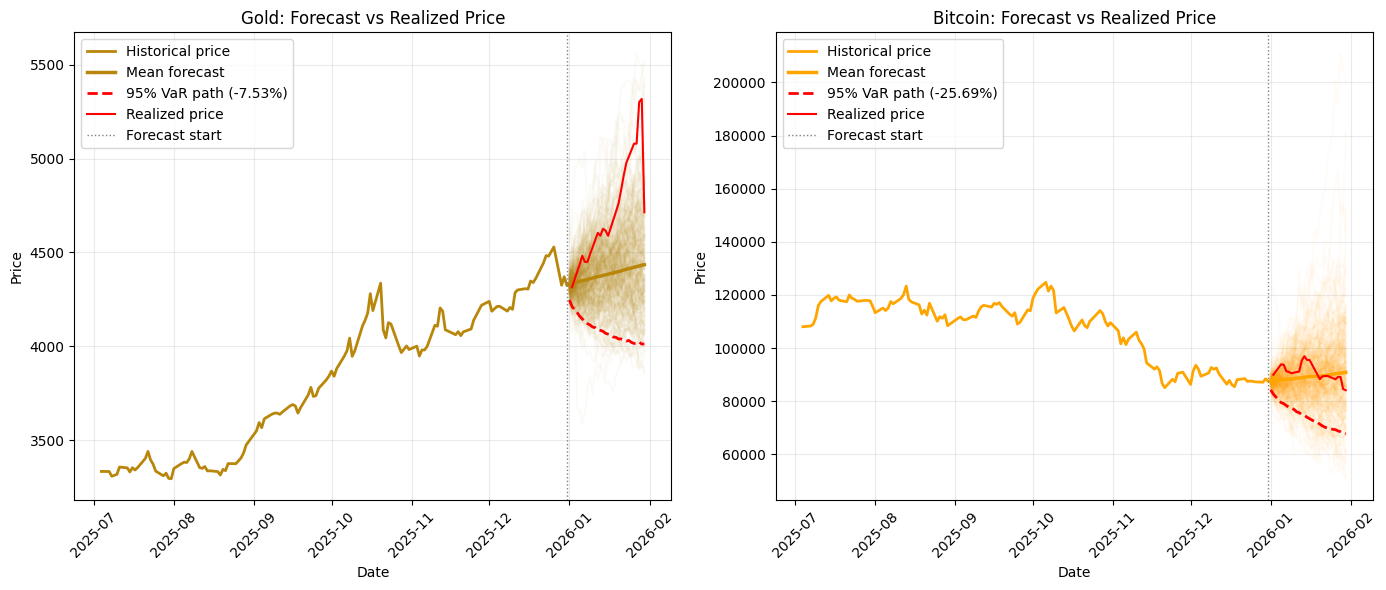

In [ ]:
def plot_price_mc_with_real(asset, prices, real_prices, sim_returns, color, title):
    last_6m = prices[asset].iloc[-126:]
    last_price = last_6m.iloc[-1]
    last_date = last_6m.index[-1]

    future_dates = pd.date_range(
        start=last_date + pd.Timedelta(days=1),
        periods=sim_returns.shape[1],
        freq="D"
    )

    price_paths = last_price * np.exp(
        np.cumsum(sim_returns / 100, axis=1)
    )

    mean_path = price_paths.mean(axis=0)
    var95_path = np.percentile(price_paths, 5, axis=0)

    var95_return = np.percentile(
        np.cumsum(sim_returns, axis=1)[:, -1],
        5
    )

    # Historical
    ax.plot(
        last_6m.index,
        last_6m.values,
        color=color,
        linewidth=2,
        label="Historical price"
    )

    # Monte Carlo paths
    ax.plot(
        future_dates,
        price_paths[:300].T,
        color=color,
        alpha=0.035
    )

    # Mean forecast
    ax.plot(
        future_dates,
        mean_path,
        color=color,
        linewidth=2.5,
        label="Mean forecast"
    )

    # 95% VaR path
    ax.plot(
        future_dates,
        var95_path,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"95% VaR path ({var95_return:.2f}%)"
    )

    # Real future prices
    real_series = real_prices[asset].dropna()

    ax.plot(
        real_series.index,
        real_series.values,
        color="red",
        linewidth=1.5,
        linestyle="-",
        label="Realized price"
    )

    ax.axvline(
        last_date,
        color="gray",
        linestyle=":",
        linewidth=1,
        label="Forecast start"
    )

    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Price")

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    ax.grid(alpha=0.25)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
plot_price_mc_with_real(
    "Gold",
    prices_df,
    real_prices_df,
    gold_paths,
    "darkgoldenrod",
    "Gold: Forecast vs Realized Price"
)

ax = axes[1]
plot_price_mc_with_real(
    "Bitcoin",
    prices_df,
    real_prices_df,
    btc_paths,
    "orange",
    "Bitcoin: Forecast vs Realized Price"
)

plt.tight_layout()
plt.show()

In [ ]:
gold_res.summary()

btc_res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             AR - EGARCH Model Results                              
====================================================================================
Dep. Variable:                      Bitcoin   R-squared:                       0.003
Mean Model:                              AR   Adj. R-squared:                  0.001
Vol Model:                           EGARCH   Log-Likelihood:               -5338.33
Distribution:      Standardized Student's t   AIC:                           10692.7
Method:                  Maximum Likelihood   BIC:                           10737.5
                                              No. Observations:                 2008
Date:                      Sun, Jun 21 2026   Df Residuals:                     2004
Time:                              15:33:43   Df Model:                            4
                                  Mean Model                                  
==============================================================================
                 coef    std err          t      P>|t|        95.0% Conf. Int.
------------------------------------------------------------------------------
Const          0.0648  5.803e-02      1.117      0.264    [-4.891e-02,  0.179]
Bitcoin[1]    -0.0452  1.987e-02     -2.277  2.281e-02 [-8.419e-02,-6.292e-03]
Bitcoin[2]     0.0229  1.959e-02      1.167      0.243  [-1.553e-02,6.126e-02]
Bitcoin[3] 4.2724e-04  1.867e-02  2.289e-02      0.982  [-3.616e-02,3.701e-02]
                             Volatility Model                             
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.0931  2.869e-02      3.243  1.183e-03 [3.682e-02,  0.149]
alpha[1]       0.1990  3.196e-02      6.227  4.753e-10   [  0.136,  0.262]
beta[1]        0.9780  7.949e-03    123.039      0.000   [  0.962,  0.994]
                              Distribution                              
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
nu             3.0497      0.231     13.192  9.764e-40 [  2.597,  3.503]
========================================================================

Covariance estimator: robust
"""

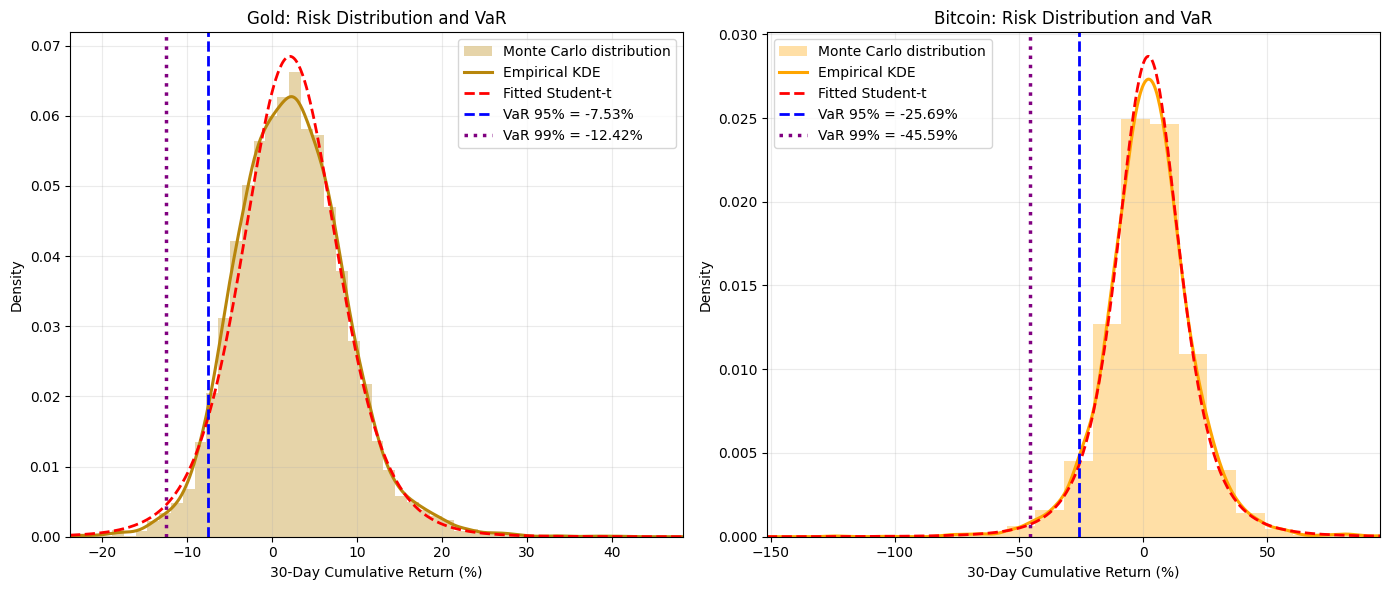

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import t, gaussian_kde

def plot_risk_distribution_professional(
    final_returns,
    color,
    title,
    zoom=True
):
    x = np.asarray(final_returns)
    x = x[np.isfinite(x)]

    # -----------------------------
    # Risk thresholds
    # -----------------------------
    var95 = np.percentile(x, 5)
    var99 = np.percentile(x, 1)

    # -----------------------------
    # Fit Student-t
    # -----------------------------
    df, loc, scale = t.fit(x)

    # -----------------------------
    # Zoom range for plotting only
    # Keeps calculations unchanged
    # -----------------------------
    if zoom:
        x_min = np.percentile(x, 0.05)
        x_max = np.percentile(x, 99.95)
    else:
        x_min = x.min()
        x_max = x.max()

    x_grid = np.linspace(x_min, x_max, 600)

    t_pdf = t.pdf(
        x_grid,
        df,
        loc=loc,
        scale=scale
    )

    kde = gaussian_kde(x)
    kde_pdf = kde(x_grid)

    # -----------------------------
    # Plot
    # -----------------------------
    ax.hist(
        x,
        bins=70,
        density=True,
        alpha=0.35,
        color=color,
        label="Monte Carlo distribution"
    )

    ax.plot(
        x_grid,
        kde_pdf,
        color=color,
        linewidth=2.2,
        label="Empirical KDE"
    )

    ax.plot(
        x_grid,
        t_pdf,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Fitted Student-t"
    )

    ax.axvline(
        var95,
        color="blue",
        linestyle="--",
        linewidth=2,
        label=f"VaR 95% = {var95:.2f}%"
    )

    ax.axvline(
        var99,
        color="purple",
        linestyle=":",
        linewidth=2.5,
        label=f"VaR 99% = {var99:.2f}%"
    )

    ax.set_xlim(x_min, x_max)

    ax.set_title(title)
    ax.set_xlabel("30-Day Cumulative Return (%)")
    ax.set_ylabel("Density")

    ax.legend()
    ax.grid(alpha=0.25)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
plot_risk_distribution_professional(
    gold_final,
    color="darkgoldenrod",
    title="Gold: Risk Distribution and VaR",
    zoom=True
)

ax = axes[1]
plot_risk_distribution_professional(
    btc_final,
    color="orange",
    title="Bitcoin: Risk Distribution and VaR",
    zoom=True
)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

beta = 0.9780

half_life = np.log(0.5) / np.log(beta)

print(f"Volatility Half-Life: {half_life:.2f} trading days")

Volatility Half-Life: 31.16 trading days


In [ ]:
print(gold_res.summary())

                            AR - GJR-GARCH Model Results                            
Dep. Variable:                         Gold   R-squared:                       0.001
Mean Model:                              AR   Adj. R-squared:                  0.001
Vol Model:                        GJR-GARCH   Log-Likelihood:               -2632.47
Distribution:      Standardized Student's t   AIC:                           5278.94
Method:                  Maximum Likelihood   BIC:                           5318.18
                                              No. Observations:                 2010
Date:                      Sun, Jun 21 2026   Df Residuals:                     2008
Time:                              15:33:43   Df Model:                            2
                                  Mean Model                                  
                 coef    std err          t      P>|t|        95.0% Conf. Int.
-----------------------------------------------------------------------------

In [ ]:
import numpy as np

beta_gold = 0.9306

hl_gold = np.log(0.5)/np.log(beta_gold)

print(hl_gold)

9.636983709705813


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# =============================
# Output folders
# =============================

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# =============================
# Save current/latest figures
# =============================

# Use these after each plot cell, before plt.show()
# Example:
# plt.savefig("figures/figure_1_forecast_mc.png", dpi=300, bbox_inches="tight")
# plt.savefig("figures/figure_1_forecast_mc.pdf", bbox_inches="tight")


In [ ]:
# Plot 1
plt.savefig("figures/figure_1_forecast_mc_realized.png", dpi=300, bbox_inches="tight")
plt.savefig("figures/figure_1_forecast_mc_realized.pdf", bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
# Plot 2
plt.savefig("figures/figure_2_risk_distribution_var.png", dpi=300, bbox_inches="tight")
plt.savefig("figures/figure_2_risk_distribution_var.pdf", bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
# Plot 3
plt.savefig("figures/figure_3_evt_gpd_fit.png", dpi=300, bbox_inches="tight")
plt.savefig("figures/figure_3_evt_gpd_fit.pdf", bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
pip install openpyxl



   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openp

In [ ]:
# =============================
# Final summary table
# =============================

final_summary_df = pd.DataFrame({
    "Metric": [
        "Final Model",
        "AIC",
        "BIC",
        "Persistence beta",
        "Volatility Half-Life",
        "Student-t nu",
        "EVT xi",
        "Mean 30D Return",
        "VaR 95%",
        "VaR 99%",
        "ES 95%",
        "ES 99%"
    ],
    "Gold": [
        "AR(1)-GJR-GARCH(1,1)-t",
        5278.94,
        5318.18,
        0.9306,
        9.64,
        4.3156,
        0.145277,
        2.469323,
        -7.441684,
        -12.497180,
        -10.615044,
        -15.272351
    ],
    "Bitcoin": [
        "AR(3)-EGARCH(1,1)-t",
        10692.66,
        10737.50,
        0.9780,
        31.16,
        3.0497,
        0.241217,
        1.968957,
        -24.192792,
        -43.865160,
        -36.724743,
        -60.317230
    ]
})

# =============================
# Export to Excel
# =============================

output_path = "results/gold_bitcoin_ar_garch_evt_results.xlsx"

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    final_summary_df.to_excel(writer, sheet_name="Final Summary", index=False)
    risk_df.to_excel(writer, sheet_name="Monte Carlo Risk", index=False)
    evt_df.to_excel(writer, sheet_name="EVT Results", index=False)
    comparison_df.to_excel(writer, sheet_name="EVT vs Empirical", index=False)
    results_df.to_excel(writer, sheet_name="Model Selection", index=False)

print(f"Saved Excel file to: {output_path}")

Saved Excel file to: results/gold_bitcoin_ar_garch_evt_results.xlsx
